In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.anova import AnovaRM
from statsmodels.multivariate.manova import MANOVA

from sklearn.decomposition import PCA


class StructureAnalyzer:

    def __init__(self,
                 DD_A, DD_B, DD_C,
                 ND_A, ND_B, ND_C,
                 group_names=("A", "B", "C")):

        self.groups = group_names

        self.DD = {
            group_names[0]: np.asarray(DD_A),
            group_names[1]: np.asarray(DD_B),
            group_names[2]: np.asarray(DD_C)
        }

        self.ND = {
            group_names[0]: np.asarray(ND_A),
            group_names[1]: np.asarray(ND_B),
            group_names[2]: np.asarray(ND_C)
        }

        self.n_trials = len(DD_A)

        self.df_rm = self._build_rm_dataframe()
        self.df_manova = self._build_manova_dataframe()

    # =====================================================
    # dataframe
    # =====================================================

    def _build_rm_dataframe(self):

        rows = []

        for trial in range(self.n_trials):

            for group in self.groups:

                rows.append({
                    "trial": trial,
                    "group": group,
                    "DD": self.DD[group][trial],
                    "ND": self.ND[group][trial]
                })

        return pd.DataFrame(rows)

    def _build_manova_dataframe(self):

        rows = []

        for group in self.groups:

            for trial in range(self.n_trials):

                rows.append({
                    "group": group,
                    "DD": self.DD[group][trial],
                    "ND": self.ND[group][trial]
                })

        return pd.DataFrame(rows)

    # =====================================================
    # RM ANOVA
    # =====================================================

    def rm_anova_dd(self):

        aov = AnovaRM(
            data=self.df_rm,
            depvar="DD",
            subject="trial",
            within=["group"]
        )

        return aov.fit()

    def rm_anova_nd(self):

        aov = AnovaRM(
            data=self.df_rm,
            depvar="ND",
            subject="trial",
            within=["group"]
        )

        return aov.fit()

    # =====================================================
    # MANOVA
    # =====================================================

    def manova(self):

        return MANOVA.from_formula(
            "DD + ND ~ group",
            data=self.df_manova
        ).mv_test()

    # =====================================================
    # PCA
    # =====================================================

    def run_pca(self):

        X = self.df_manova[["DD", "ND"]].values

        pca = PCA(n_components=2)

        scores = pca.fit_transform(X)

        result = self.df_manova.copy()

        result["PC1"] = scores[:, 0]
        result["PC2"] = scores[:, 1]

        return pca, result

    # =====================================================
    # Boxplot
    # =====================================================

    def plot_dd_box(self):

        plt.figure(figsize=(5, 4))

        plt.boxplot(
            [self.DD[g] for g in self.groups],
            tick_labels=self.groups
        )

        plt.ylabel("Diagonal Dominance")
        plt.title("DD")
        plt.tight_layout()

        plt.show()

    def plot_nd_box(self):

        plt.figure(figsize=(5, 4))

        plt.boxplot(
            [self.ND[g] for g in self.groups],
            tick_labels=self.groups
        )

        plt.ylabel("Normalized Distance")
        plt.title("ND")
        plt.tight_layout()

        plt.show()

    # =====================================================
    # DD-ND Structure Space
    # =====================================================

    def plot_structure_space(self):

        plt.figure(figsize=(6, 5))

        for g in self.groups:

            plt.scatter(
                self.DD[g],
                self.ND[g],
                label=g,
                s=60
            )

        plt.xlabel("DD")
        plt.ylabel("ND")

        plt.title("Structure Space")

        plt.legend()

        plt.tight_layout()

        plt.show()

    # =====================================================
    # PCA Plot
    # =====================================================

    def plot_pca(self):

        pca, result = self.run_pca()

        plt.figure(figsize=(6, 5))

        for g in self.groups:

            sub = result[result["group"] == g]

            plt.scatter(
                sub["PC1"],
                sub["PC2"],
                label=g,
                s=60
            )

        plt.xlabel(
            f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
        )

        plt.ylabel(
            f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
        )

        plt.title("PCA of DD + ND")

        plt.legend()

        plt.tight_layout()

        plt.show()

    # =====================================================
    # summary
    # =====================================================

    def summary(self):

        print("\n========== RM-ANOVA DD ==========")
        print(self.rm_anova_dd())

        print("\n========== RM-ANOVA ND ==========")
        print(self.rm_anova_nd())

        print("\n========== MANOVA ==========")
        print(self.manova())

In [26]:
import pickle


stat_df_path = r"F:\Hou.T.N\ID-mRSFC-ISOI\data\output\WT\statistics.pkl"
with open(stat_df_path, "rb") as f:
    stat = pickle.load(f)

In [27]:
print(stat.columns)
print(stat.index)
print(stat.loc["None", "1Trial"][3]["diagonal_dominance"])
print(stat.loc["None", "1Trial"][3]["normalized_distance_to_diagonal"])

Index(['1Trial', '2Trial', '3Trial', '4Trial', '5Trial', '6Trial', '7Trial'], dtype='str')
Index(['SM_VIS_AUD', 'PF_LAT_MED', 'None', 'AUDv'], dtype='str')
0.19992451043889922
0.32583377741005964


In [35]:
Atlas = [["SM", "VIS", "AUD"], ["PF", "LAT", "MED"], ["None"]]

DD = [[], [], []]
ND = [[], [], []]
for trial in stat.columns:

    exclude = "AUDv"
    systems = [s for s in stat.index.tolist() if s not in exclude]

    data_dict = {}
    for sys in systems:

        cell = stat.loc[sys, trial]

        data_dict[sys] = {
            "group": np.array(cell[0]),
            "indiv": np.array(cell[1]),
            "rel": np.array(cell[2]),
            "DD": cell[3]["diagonal_dominance"],
            "ND": cell[3]["normalized_distance_to_diagonal"],
        }

    for sys in systems:
        if sys in "_".join(Atlas[0]):
            idx = 0
        elif sys in "_".join(Atlas[1]):
            idx = 1
        else:
            idx = 2
        
        DD[idx].append(data_dict[sys]["DD"])
        ND[idx].append(data_dict[sys]["ND"])
    
print(f"DD: {DD}")
print(f"ND: {ND}")

DD: [[np.float64(0.14202467888892878), np.float64(0.15298387557837906), np.float64(0.1613776989371549), np.float64(0.15433675267568603), np.float64(0.1596964797525175), np.float64(0.15679998094888642), np.float64(0.16484134899658384)], [np.float64(0.18860025848065953), np.float64(0.177800632369708), np.float64(0.18807570833875686), np.float64(0.1824043996148716), np.float64(0.18525985546502355), np.float64(0.18927891567226096), np.float64(0.1937004473706875)], [np.float64(0.19992451043889922), np.float64(0.1979135199911115), np.float64(0.20288660653601376), np.float64(0.1934412272692895), np.float64(0.1979968103504337), np.float64(0.19749828075650436), np.float64(0.19968031793905008)]]
ND: [[np.float64(0.35392194499839935), np.float64(0.35414846133018985), np.float64(0.34858855936400146), np.float64(0.3539722420864967), np.float64(0.354081597794041), np.float64(0.353230366495219), np.float64(0.349067861843447)], [np.float64(0.32720376903014703), np.float64(0.33840339170082845), np.floa

In [42]:
analyzer = StructureAnalyzer(
    DD[2], DD[1], DD[0],
    ND[2], ND[1], ND[0]
)

In [43]:
analyzer.summary()


========== RM-ANOVA DD ==========
               Anova
      F Value  Num DF  Den DF Pr > F
------------------------------------
group 150.2936 2.0000 12.0000 0.0000


========== RM-ANOVA ND ==========
               Anova
      F Value  Num DF  Den DF Pr > F
------------------------------------
group 314.7520 2.0000 12.0000 0.0000


========== MANOVA ==========
                     Multivariate linear model
                                                                   
-------------------------------------------------------------------
       Intercept          Value    Num DF  Den DF  F Value   Pr > F
-------------------------------------------------------------------
          Wilks' lambda     0.0001 2.0000 17.0000 85422.1322 0.0000
         Pillai's trace     0.9999 2.0000 17.0000 85422.1322 0.0000
 Hotelling-Lawley trace 10049.6626 2.0000 17.0000 85422.1322 0.0000
    Roy's greatest root 10049.6626 2.0000 17.0000 85422.1322 0.0000
-------------------------------------------

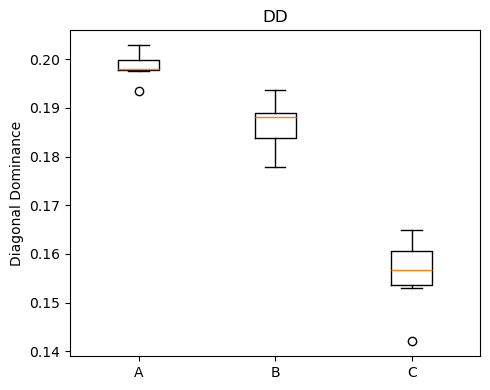

In [44]:
analyzer.plot_dd_box()

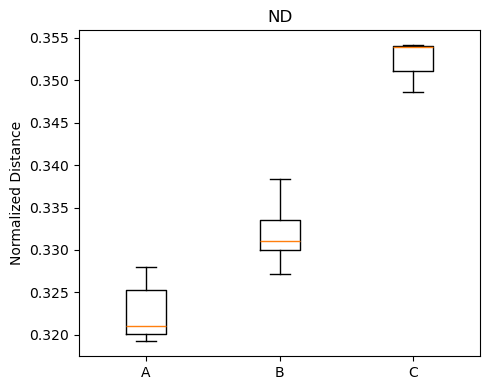

In [45]:
analyzer.plot_nd_box()

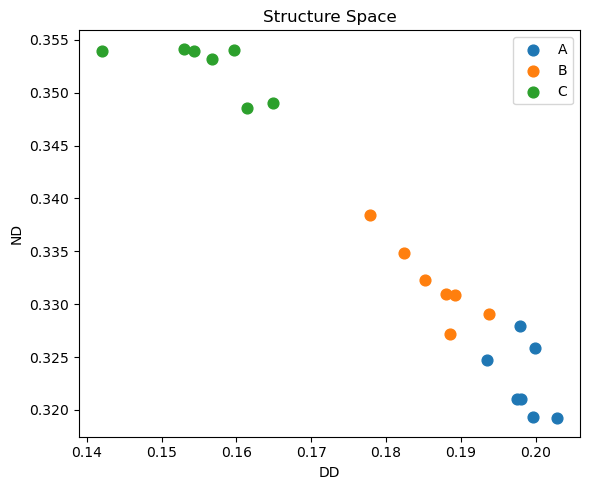

In [46]:
analyzer.plot_structure_space()

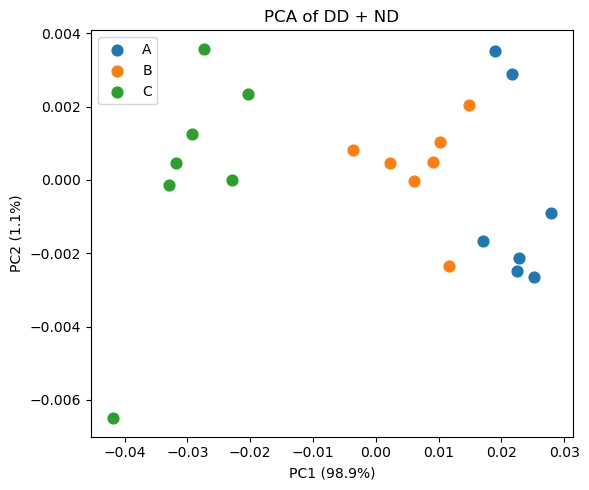

In [47]:
analyzer.plot_pca()